# 12 · Ensemble experiments

## Purpose

Compare out-of-fold probability averaging with its individual members and retain blending only when the validation improvement is measured.

## Method

Build out-of-fold predictions for the two strongest available CV candidates. Compare soft probability means on identical folds; no in-sample probabilities are used.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

Only pairwise mean blends are benchmarked in this baseline. Stacking is not added unless data volume and a separate nested evaluation justify it.

## References

Ensemble and validation design notes are in docs/implementation_plan.md.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '12 · Ensemble experiments')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 12 · Ensemble experiments


,blend,roc_auc,pr_auc,fit_seconds_total,inference_seconds_total,rss_delta_mb_total
0,OOF mean: HistGradientBoosting + Logistic regr...,0.587330,0.553282,15.782665,1.825988,47.417969
1,HistGradientBoosting,0.585602,0.551155,10.220954,1.288796,29.597656
2,Logistic regression,0.585378,0.550909,5.561712,0.537192,17.820312


Best single-model OOF ROC-AUC: 0.585601761369573
Best probability blend OOF ROC-AUC: 0.587330480156792
Blend retained for nested calibration and holdout study: Soft voting: HistGradientBoosting + Logistic regression


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5616\4177797530.py:32: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


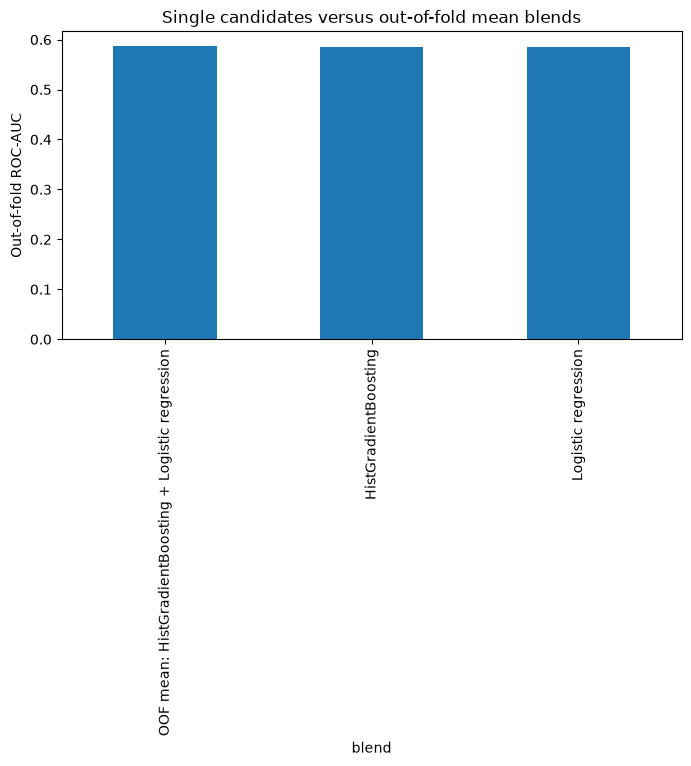

In [2]:
from returnwise.models import evaluate_probability_blend, model_registry
from returnwise.research_state import load_state, save_state
import matplotlib.pyplot as plt
import pandas as pd

state = load_state()
cv_parts = [x for x in [state.get('baseline_results'), state.get('advanced_results')] if x is not None]
cv_results = pd.concat(cv_parts, ignore_index=True) if cv_parts else pd.DataFrame()
completed = cv_results[cv_results['status'] == 'completed'].sort_values('roc_auc', ascending=False)
registry, skipped = model_registry(state['X_train'], mode=state.get('experiment_mode', 'quick'))
members = [name for name in completed['model'].tolist() if name in registry][:2]
blend_candidate = None
if len(members) < 2:
    print('Fewer than two candidate families completed validation; no ensemble was evaluated.')
    blend_results, oof_probabilities = pd.DataFrame(), {}
else:
    blend_results, oof_probabilities = evaluate_probability_blend(
        state['X_train'], state['y_train'], members, mode=state.get('experiment_mode', 'quick'), seed=42
    )
    display(blend_results)
    single_rows = blend_results[~blend_results['blend'].str.startswith('OOF mean: ')]
    pair_rows = blend_results[blend_results['blend'].str.startswith('OOF mean: ')]
    baseline_best = float(single_rows['roc_auc'].max())
    best_blend_row = pair_rows.sort_values('roc_auc', ascending=False).iloc[0] if not pair_rows.empty else None
    best_blend = float(best_blend_row['roc_auc']) if best_blend_row is not None else float('-inf')
    blend_candidate = 'Soft voting: ' + best_blend_row['blend'].replace('OOF mean: ', '') if best_blend > baseline_best else None
    print('Best single-model OOF ROC-AUC:', baseline_best)
    print('Best probability blend OOF ROC-AUC:', best_blend)
    print('Blend retained for nested calibration and holdout study:', blend_candidate)
    ax = blend_results.plot.bar(x='blend', y='roc_auc', figsize=(8, 4), legend=False, title='Single candidates versus out-of-fold mean blends')
    ax.set_ylabel('Out-of-fold ROC-AUC')
    plt.tight_layout()
    plt.show()
state.update({'blend_results': blend_results, 'oof_probabilities': oof_probabilities,
              'selected_ensemble': blend_candidate})
from returnwise.experiments import log_experiment
log_experiment('OOF probability blend benchmark', None, {'results': blend_results.to_dict(orient='records')},
               {'members': members, 'selected_ensemble': blend_candidate})
save_state(state)
